# Exercice 6 : Le registre des incidents et la réponse à l'auditeur

> **En une phrase :** certains incidents doivent être **déclarés** aux autorités et aux personnes touchées, dans un **délai** : la loi dit lesquels, et quand.

**Les demandes de l'auditeur traitées ici :** D-07 (registre des incidents, **critique**) et D-08 (lettre de réponse). Références : Loi 25 (art. 3.5 à 3.8), RGPD (art. 33 et 34).

**Le scénario.** Le service de soutien a ouvert 7 tickets d'incident en 2026. L'auditeur veut le **registre des incidents de confidentialité**,
que la Loi 25 rend obligatoire, et la preuve que les notifications exigées ont été faites à temps. Puis on écrit la lettre de réponse et on vise l'objectif : **80/100**.

**Le plan.**
1. Ce que disent les lois, en bref.
2. Quels tickets sont des incidents de confidentialité ?
3. À vous : y a-t-il un risque de préjudice sérieux ?
4. Qui aviser, et avant quand ?
5. Déposer le registre.
6. La lettre de réponse et le verdict final.

## Étape 0 : exécutez cette cellule en premier
En local, ouvrez **le dossier du chapitre** dans VS Code. Sur Colab, la cellule télécharge le dossier. Elle doit afficher **Prêt : True**.

In [1]:
# Étape 0 : sur Colab, récupère le dossier du chapitre depuis GitHub. En local (VS Code), cette cellule ne fait rien.
import os
if not os.path.exists('auditeur.py'):
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/Code-8INF857---2026.git /content/cours
    %cd "/content/cours/Chapitre 8 - Cadres réglementaires"
print('Prêt :', os.path.exists('auditeur.py'))

Prêt : True


## Étape 1 : Ce que disent les lois, en bref

| | Loi 25 (Québec) | RGPD (Europe) |
|---|---|---|
| **Qu'est-ce qu'un incident ?** | accès, utilisation ou communication **non autorisés** d'un renseignement personnel, ou sa **perte** | violation de données personnelles (destruction, perte, divulgation, accès non autorisés) |
| **Registre** | **tous** les incidents de confidentialité, même mineurs (art. 3.8) | toutes les violations (art. 33.5) |
| **Aviser l'autorité** | la **CAI**, avec diligence, si risque de **préjudice sérieux** (art. 3.5) | l'autorité (la **CNIL** en France), **dans les 72 h** après en avoir pris connaissance, sauf si le risque est **improbable** (art. 33) |
| **Aviser les personnes** | oui, si risque de préjudice sérieux | oui, si risque **élevé** (art. 34) |

Le « préjudice sérieux » s'évalue avec trois facteurs (art. 3.7) : la **sensibilité** des renseignements, les **conséquences** appréhendées, et la **probabilité** qu'ils soient utilisés à des fins préjudiciables.

*Simplification pour l'exercice : on traduit ces critères en règles. Dans la vraie vie, c'est une évaluation au cas par cas, documentée, faite avec le responsable de la protection des renseignements personnels.*

## Étape 2 : Les incidents de confidentialité
**Ce qu'on fait :** on lit les 7 tickets. Un ticket est un **incident de confidentialité** s'il touche des renseignements personnels **et** s'il y a eu accès, communication ou perte.

In [2]:
from helper import lire_csv, deposer, afficher_md
import pandas as pd

tickets = lire_csv('tickets_incidents_2026.csv')
tickets['incident_confidentialite'] = (tickets['renseignements_personnels'] == 'oui') & tickets['nature'].isin(['accès', 'communication', 'perte'])
pd.set_option('display.max_colwidth', 90)
tickets[['ticket', 'resume', 'nature', 'incident_confidentialite']]

,ticket,resume,nature,incident_confidentialite
0,INC-2026-011,"Courriel d'hameçonnage signalé par 6 employés ; aucun clic, aucun identifiant saisi",aucune,False
1,INC-2026-019,"Facture d'un client envoyée par erreur à un autre client, qui l'a supprimée et l'a con...",communication,True
2,INC-2026-027,"Portable d'une représentante volé dans sa voiture ; disque chiffré BitLocker, clé non ...",perte,True
3,INC-2026-034,"Attaque DDoS sur web01 et web02, 3 h d'interruption",aucune,False
4,INC-2026-041,Connexion à bd01 avec le compte d'un administrateur parti le 29 août ; export de la ta...,accès,True
5,INC-2026-046,Rançongiciel sur un poste non inventorié (DESKTOP-7KQ2M1) ; aucune donnée personnelle ...,aucune,False
6,INC-2026-052,"Le scan réseau révèle un NAS (10.0.1.47) accessible à tous, contenant 45 CV de candida...",accès,True


**👀 Ce qu'on doit voir :** 4 incidents de confidentialité sur 7. Le DDoS (INC-034) et le rançongiciel sur un poste sans données personnelles (INC-046) sont des incidents de **sécurité**, pas de **confidentialité** : ils vont dans le registre des incidents de sécurité, pas dans celui que demande la Loi 25.

Même la facture envoyée au mauvais client (INC-019) est un incident de confidentialité : elle va **au registre**, même si personne n'est avisé.

## À vous : le risque de préjudice sérieux
Complétez `prejudice_serieux(t)` avec la règle suivante. Il y a risque de préjudice sérieux si c'est un incident de confidentialité, que les données **n'étaient pas chiffrées**, et que :
- la sensibilité est `élevée`, **ou**
- une utilisation malveillante est `probable`.

Les colonnes utiles : `incident_confidentialite`, `donnees_chiffrees` (`oui`/`non`), `sensibilite`, `utilisation_malveillante`.

In [3]:
def prejudice_serieux(t):
    # À VOUS
    return False

tickets['prejudice_serieux'] = tickets.apply(prejudice_serieux, axis=1)
tickets[['ticket', 'sensibilite', 'donnees_chiffrees', 'utilisation_malveillante', 'prejudice_serieux']]

,ticket,sensibilite,donnees_chiffrees,utilisation_malveillante,prejudice_serieux
0,INC-2026-011,,,,False
1,INC-2026-019,faible,non,improbable,False
2,INC-2026-027,moyenne,oui,improbable,False
3,INC-2026-034,,,,False
4,INC-2026-041,élevée,non,probable,False
5,INC-2026-046,,,,False
6,INC-2026-052,élevée,non,possible,False


*Réponse :*
```python
def prejudice_serieux(t):
    return bool(t['incident_confidentialite'] and t['donnees_chiffrees'] != 'oui'
                and (t['sensibilite'] == 'élevée' or t['utilisation_malveillante'] == 'probable'))
```
Attendu : **INC-041** (export de la table clients avec le compte d'un ancien administrateur) et **INC-052** (CV avec numéros d'assurance sociale sur un NAS ouvert à tous).
Le portable volé (INC-027) ne l'est pas : **le chiffrement** a fait toute la différence.

## Étape 3 : Qui aviser, et avant quand ?
**Ce qu'on fait :**
- **CAI** : risque de préjudice sérieux et au moins une personne au Québec ;
- **CNIL** : incident de confidentialité touchant au moins une personne en France, sauf si le risque est improbable ; **échéance = détection + 72 h**.

In [4]:
tickets['aviser_cai'] = tickets['prejudice_serieux'] & (tickets['personnes_quebec'].astype(int) > 0)
tickets['aviser_cnil'] = (tickets['incident_confidentialite'] & (tickets['personnes_france'].astype(int) > 0)
                          & (tickets['utilisation_malveillante'] != 'improbable'))
tickets['echeance_cnil'] = [(pd.Timestamp(d) + pd.Timedelta(hours=72)).strftime('%Y-%m-%dT%H:%M') if c else ''
                            for d, c in zip(tickets['detecte_le'], tickets['aviser_cnil'])]
tickets[['ticket', 'detecte_le', 'personnes_quebec', 'personnes_france', 'aviser_cai', 'aviser_cnil', 'echeance_cnil']]

,ticket,detecte_le,personnes_quebec,personnes_france,aviser_cai,aviser_cnil,echeance_cnil
0,INC-2026-011,2026-02-03T09:40,0,0,False,False,
1,INC-2026-019,2026-03-17T14:05,1,0,False,False,
2,INC-2026-027,2026-04-22T08:15,120,0,False,False,
3,INC-2026-034,2026-06-30T11:20,0,0,False,False,
4,INC-2026-041,2026-09-14T08:02,1240,310,False,True,2026-09-17T08:02
5,INC-2026-046,2026-10-08T16:45,0,0,False,False,
6,INC-2026-052,2026-11-23T10:30,45,0,False,False,


**👀 Ce qu'on doit voir :** avec votre règle, **INC-041** doit être déclaré à la **CAI** et à la **CNIL** (310 personnes en France), à la CNIL avant le **17 septembre 2026 à 08:02**. **INC-052** doit être déclaré à la CAI seulement.

Sans votre tâche, `aviser_cai` vaut `False` partout, mais la CNIL reste à aviser pour INC-041 : le seuil du RGPD (« sauf si le risque est improbable ») est **plus bas** que celui de la Loi 25 (« risque de préjudice sérieux »). Le même incident n'a pas les mêmes obligations des deux côtés de l'Atlantique.

**❓ Question pour la classe :** relisez les ex. 2 et 4. D'où viennent les deux incidents graves de l'année ?

*Piste : INC-041 vient d'un **compte d'administrateur jamais désactivé** après un départ (ex4 : `pbouchard`, encore dans `sudo` sur bd01). INC-052 vient d'un **NAS que personne n'avait inventorié** (ex2 : 10.0.1.47). Les deux contrôles « ennuyeux » de l'audit, l'inventaire et la revue des accès, auraient évité les deux incidents.*

## Étape 4 : Déposer le registre D-07

In [5]:
colonnes = ['ticket', 'detecte_le', 'resume', 'incident_confidentialite', 'prejudice_serieux', 'aviser_cai', 'aviser_cnil', 'echeance_cnil']
registre = tickets[colonnes].copy()
for c in ['incident_confidentialite', 'prejudice_serieux', 'aviser_cai', 'aviser_cnil']:
    registre[c] = registre[c].map({True: 'oui', False: 'non'})
deposer('registre_incidents.csv', registre);

Pièce déposée : livrables/registre_incidents.csv


## Étape 5 : La lettre de réponse (D-08)
**Ce qu'on fait :** l'auditeur attend une courte lettre qui reprend chaque demande : ce qu'on dépose, ce qu'on a trouvé, ce qu'on fait.
On la **génère** à partir des pièces déposées, pour que les chiffres soient exacts. Relisez-la et corrigez le texte si vous voulez : c'est votre signature.

In [6]:
import os
lire = lambda f: pd.read_csv(f'livrables/{f}', dtype=str, keep_default_na=False) if os.path.exists(f'livrables/{f}') else pd.DataFrame()
app, inv, ctl, acc, rsq, inc = (lire(f) for f in ['applicabilite.csv', 'inventaire.csv', 'controles.csv',
                                                  'revue_acces.csv', 'registre_risques.csv', 'registre_incidents.csv'])
nb = lambda df, col, val: int((df[col] == val).sum()) if col in df else 0
cout_total = f"{pd.to_numeric(rsq['cout']).sum():,.0f}".replace(',', ' ') if 'cout' in rsq else '0'

lettre = f'''# NordHébergement inc. — Réponse à la lettre d'audit du 16 novembre 2026

## D-01 Textes applicables
Nous avons analysé {len(app)} textes ; {nb(app, 'applicable', 'oui')} s'appliquent à nous (dont la Loi 25, le RGPD et ISO 27001 par contrat). Voir applicabilite.csv.

## D-02 Inventaire des actifs
Le rapprochement avec le scan du 23 novembre a révélé {nb(inv, 'statut', 'non inventorié')} actif(s) non inventorié(s) et {nb(inv, 'statut', 'introuvable')} introuvable(s) ; chacun a maintenant un propriétaire.

## D-03 Configuration sécurisée
{nb(ctl, 'resultat', 'non conforme')} contrôle(s) non conforme(s), surtout sur bd01 ; chacun a une preuve et une action corrective datée.

## D-04 Sauvegardes
Les sauvegardes de bd01 échouaient depuis le 11 novembre et n'avaient jamais été testées ; réparation et test de restauration planifiés avant votre visite.

## D-05 Revue des accès
{len(acc)} anomalie(s) trouvée(s), dont {nb(acc, 'anomalie', 'parti_actif')} compte(s) d'employés partis encore actifs ; toutes ont une action corrective.

## D-06 Risques
{len(rsq)} risques évalués et traités pour {cout_total} $, dans le budget de 50 000 $ ; aucun risque résiduel au-dessus de notre appétit (8).

## D-07 Incidents
{nb(inc, 'incident_confidentialite', 'oui')} incident(s) de confidentialité inscrits au registre ; {nb(inc, 'aviser_cai', 'oui')} avis à la CAI et {nb(inc, 'aviser_cnil', 'oui')} à la CNIL.

*L'équipe TI de NordHébergement*
'''
deposer('reponse_auditeur.md', lettre)
afficher_md(lettre)

Pièce déposée : livrables/reponse_auditeur.md


# NordHébergement inc. — Réponse à la lettre d'audit du 16 novembre 2026

## D-01 Textes applicables
Nous avons analysé 9 textes ; 3 s'appliquent à nous (dont la Loi 25, le RGPD et ISO 27001 par contrat). Voir applicabilite.csv.

## D-02 Inventaire des actifs
Le rapprochement avec le scan du 23 novembre a révélé 2 actif(s) non inventorié(s) et 1 introuvable(s) ; chacun a maintenant un propriétaire.

## D-03 Configuration sécurisée
5 contrôle(s) non conforme(s), surtout sur bd01 ; chacun a une preuve et une action corrective datée.

## D-04 Sauvegardes
Les sauvegardes de bd01 échouaient depuis le 11 novembre et n'avaient jamais été testées ; réparation et test de restauration planifiés avant votre visite.

## D-05 Revue des accès
9 anomalie(s) trouvée(s), dont 3 compte(s) d'employés partis encore actifs ; toutes ont une action corrective.

## D-06 Risques
8 risques évalués et traités pour 65 500 $, dans le budget de 50 000 $ ; aucun risque résiduel au-dessus de notre appétit (8).

## D-07 Incidents
4 incident(s) de confidentialité inscrits au registre ; 0 avis à la CAI et 1 à la CNIL.

*L'équipe TI de NordHébergement*


## Le verdict final
**Ce qu'on fait :** on relance l'auditeur sur le dossier complet, puis on regarde la progression du score au fil de vos dépôts.

In [7]:
import auditeur
auditeur.auditer();

Cabinet Boréal Audit — revue des pièces déposées

⚠️ D-01 Textes applicables et justification          9.3 / 10
      · nis2 : applicabilité « ? » incorrecte
      · nis2 : justification manquante ou trop courte
⚠️ D-02 Inventaire des actifs rapproché du réseau   14.2 / 15  (critique)
      · 10.0.1.47 : aucun propriétaire
      · 10.0.3.58 : aucun propriétaire
✅ D-03 Configuration sécurisée des serveurs        15.0 / 15
❌ D-04 Sauvegardes et test de restauration          0.0 / 10  (critique)
      · web01 / sauvegarde_24h : absent
      · web01 / test_restauration_12_mois : absent
      · bd01 / sauvegarde_24h : absent
      · bd01 / test_restauration_12_mois : absent
⚠️ D-05 Revue des droits d'accès                    11.2 / 15  (critique)
      · anomalie non trouvée : aroy sur bd01 (admin_injustifie)
      · anomalie non trouvée : deploy sur web01 (sans_proprietaire)
      · anomalie non trouvée : pbouchard sur bd01 (parti_actif)
⚠️ D-06 Registre et plan de traitement des risques  

**👀 Ce qu'on doit voir :** sans les tâches « À vous » : **75 / 100** et ❌ **certification reportée**, car D-04 (critique) est refusée. On est tout près de 80, mais une seule demande critique refusée suffit.
Avec les six tâches : **100 / 100**, ✅ **recommandé pour la certification**. Le graphique montre la montée du score à chaque dépôt.

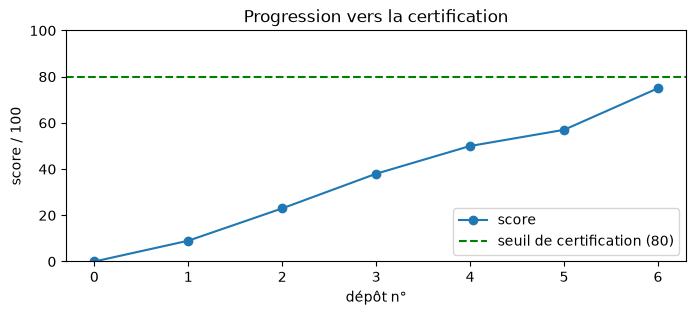

In [8]:
auditeur.progression()

**❓ Question pour la classe :** l'auditeur recommande la certification alors que `bd01` est non conforme partout et qu'il y a eu deux incidents graves. Est-ce normal ?

*Piste : oui. La certification ne dit pas « cette entreprise n'a pas de problèmes » ; elle dit « cette entreprise **connaît** ses risques, les **mesure**, les **traite**, et le **prouve** ». C'est la différence entre la sécurité (ne pas se faire attaquer) et la conformité (pouvoir montrer qu'on gère la sécurité). Il faut les deux.*

## Ce qu'il faut retenir
- La Loi 25 oblige à tenir un **registre de tous** les incidents de confidentialité, et à aviser la **CAI** et les personnes en cas de **risque de préjudice sérieux**.
- Le RGPD impose d'aviser l'autorité **dans les 72 h** : le délai part du moment où on **prend connaissance** de l'incident, pas de la fin de l'enquête.
- **Chiffrer** les données change tout : le même vol devient un incident mineur.
- Un audit est un **tout** : l'inventaire (ex2) et la revue des accès (ex4) auraient évité les deux incidents graves (ex6).
- Un dossier de conformité, c'est : savoir ce qui s'applique, **prouver** où on en est, **traiter** les écarts avec un plan, et **expliquer** le tout.